# IBM AML (AMLSim) — Exploratory Data Analysis

**Dataset:** `LI-Small_accounts.csv` (node metadata) + `LI-Small_transactions.csv` (directed edge list)

Money laundering is a *relational* problem, so this notebook treats the data as a graph from the start:
accounts are nodes, transactions are directed edges. The EDA is organised to answer the questions that
actually drive downstream modelling decisions:

| Section | Question it answers |
|---|---|
| 1–2 | What is actually in these files, and do they join cleanly? |
| 3 | Is the data trustworthy (nulls, dupes, orphan accounts)? |
| 4 | How severe is the class imbalance? |
| 5–6 | What do amounts, currencies and payment rails look like? |
| 7 | Is there temporal structure or burstiness? |
| 8–9 | What does the transaction network look like (degree, hubs, cycles)? |
| 10 | Is there evidence of structuring/smurfing near reporting thresholds? |
| 11 | How do laundering accounts differ from clean ones? |
| 12 | What features and modelling choices does the data justify? |

> **Note on column names.** The public IBM AML files ship with two columns literally both named
> `Account` (sender and receiver). Pandas silently renames the second to `Account.1`. This notebook
> normalises that and several other naming variants up front — do not skip Section 1.

## 0. Configuration

In [15]:
from pathlib import Path

# --- EDIT THESE ---------------------------------------------------------
DATA_DIR = Path("./data")                       # folder holding the CSVs
TX_FILE       = DATA_DIR / "LI-Small_Trans.csv"
ACCOUNTS_FILE = DATA_DIR / "LI-Small_accounts.csv"

# LI-Small has ~7M transaction rows. Set to an int (e.g. 2_000_000) to sample
# while developing, then set to None for the full pass.
NROWS = None

GRAPH_SAMPLE_EDGES = 500_000   # cap for the NetworkX section (memory guard)
RANDOM_SEED        = 42
OUT_DIR            = Path("./eda_output")
# ------------------------------------------------------------------------

OUT_DIR.mkdir(exist_ok=True, parents=True)
print("Transactions:", TX_FILE, "| exists:", TX_FILE.exists())
print("Accounts:    ", ACCOUNTS_FILE, "| exists:", ACCOUNTS_FILE.exists())

Transactions: data/LI-Small_Trans.csv | exists: True
Accounts:     data/LI-Small_accounts.csv | exists: True


In [16]:
import warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

warnings.filterwarnings("ignore")
np.random.seed(RANDOM_SEED)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

plt.rcParams.update({
    "figure.figsize": (11, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

def thousands(ax, axis="y"):
    fmt = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)
    return ax

print("pandas", pd.__version__, "| numpy", np.__version__)

pandas 2.3.3 | numpy 2.3.3


## 1. Load & normalise schema

The loader below is deliberately defensive. It maps whatever header variant is present onto a canonical
schema so every downstream cell can rely on fixed names.

In [17]:
CANONICAL_TX = {
    "timestamp":       ["Timestamp", "timestamp", "Date"],
    "from_bank":       ["From Bank", "from_bank", "Sender Bank"],
    "to_bank":         ["To Bank", "to_bank", "Receiver Bank"],
    "from_account":    ["Account", "From Account", "from_account", "Sender Account", "nameOrig"],
    "to_account":      ["Account.1", "To Account", "to_account", "Receiver Account", "nameDest"],
    "amount_received": ["Amount Received", "amount_received"],
    "currency_received":["Receiving Currency", "Amount Received Currency"],
    "amount_paid":     ["Amount Paid", "amount_paid", "Amount"],
    "currency_paid":   ["Payment Currency", "Amount Paid Currency"],
    "payment_format":  ["Payment Format", "payment_format", "Payment Type"],
    "is_laundering":   ["Is Laundering", "is_laundering", "isFraud", "Label"],
}

CANONICAL_ACC = {
    "account_id":   ["Account Number", "Account ID", "Account", "account_id", "acct_id"],
    "bank_id":      ["Bank Name", "Bank", "Bank ID", "bank_id"],
    "entity_id":    ["Entity ID", "Customer ID", "customer_id", "entity_id"],
    "account_type": ["Account Type", "account_type", "Type"],
    "country":      ["Country", "country"],
    "flag":         ["Is Laundering", "Is SAR", "is_sar", "Flag"],
}


def normalise(df, mapping, label):
    # Rename recognised columns to canonical names; report what was and wasn't matched.
    rename, taken = {}, set()
    for canon, candidates in mapping.items():
        for c in candidates:
            if c in df.columns and c not in taken:
                rename[c] = canon
                taken.add(c)
                break
    out = df.rename(columns=rename)
    matched  = sorted(rename.values())
    unmapped = [c for c in df.columns if c not in rename]
    print(f"[{label}] mapped {len(matched)} columns -> {matched}")
    if unmapped:
        print(f"[{label}] left as-is: {unmapped}")
    return out

In [18]:
tx_raw = pd.read_csv(TX_FILE, nrows=NROWS, low_memory=False)
print("raw transaction columns:", list(tx_raw.columns))
tx = normalise(tx_raw, CANONICAL_TX, "transactions")
del tx_raw; gc.collect()

tx.head(5)

raw transaction columns: ['Timestamp', 'From Bank', 'Account', 'To Bank', 'Account.1', 'Amount Received', 'Receiving Currency', 'Amount Paid', 'Payment Currency', 'Payment Format', 'Is Laundering']
[transactions] mapped 11 columns -> ['amount_paid', 'amount_received', 'currency_paid', 'currency_received', 'from_account', 'from_bank', 'is_laundering', 'payment_format', 'timestamp', 'to_account', 'to_bank']


,timestamp,from_bank,from_account,to_bank,to_account,amount_received,currency_received,amount_paid,currency_paid,payment_format,is_laundering
0,2022/09/01 00:08,11,8000ECA90,11,8000ECA90,"3,195,403.0000",US Dollar,"3,195,403.0000",US Dollar,Reinvestment,0
1,2022/09/01 00:21,3402,80021DAD0,3402,80021DAD0,"1,858.9600",US Dollar,"1,858.9600",US Dollar,Reinvestment,0
2,2022/09/01 00:00,11,8000ECA90,1120,8006AA910,"592,571.0000",US Dollar,"592,571.0000",US Dollar,Cheque,0
3,2022/09/01 00:16,3814,8006AD080,3814,8006AD080,12.3200,US Dollar,12.3200,US Dollar,Reinvestment,0
4,2022/09/01 00:00,20,8006AD530,20,8006AD530,"2,941.5600",US Dollar,"2,941.5600",US Dollar,Reinvestment,0


In [58]:
print([curr for curr in tx['currency_paid'].unique()])

['US Dollar', 'Euro', 'Bitcoin', 'Yuan', 'Yen', 'UK Pound', 'Brazil Real', 'Australian Dollar', 'Rupee', 'Ruble', 'Canadian Dollar', 'Mexican Peso', 'Swiss Franc', 'Shekel', 'Saudi Riyal']


In [19]:
if ACCOUNTS_FILE.exists():
    acc_raw = pd.read_csv(ACCOUNTS_FILE, low_memory=False)
    print("raw account columns:", list(acc_raw.columns))
    acc = normalise(acc_raw, CANONICAL_ACC, "accounts")
    del acc_raw; gc.collect()
    display(acc.head(5))
else:
    acc = None
    print("!! accounts file not found — node-metadata sections will be skipped.")

raw account columns: ['Bank Name', 'Bank ID', 'Account Number', 'Entity ID', 'Entity Name']
[accounts] mapped 3 columns -> ['account_id', 'bank_id', 'entity_id']
[accounts] left as-is: ['Bank ID', 'Entity Name']


,bank_id,Bank ID,account_id,entity_id,Entity Name
0,China Bank #2820,314693,81B86A280,800D8CCF0,Corporation #41344
1,France Bank #4585,311253,8187FEA80,800B505E0,Corporation #54497
2,China Bank #2242,39996,803961E00,800D03F60,Partnership #36904
3,National Bank of Newport,331440,81B075800,801567C10,Corporation #16224
4,UK Bank #33,135417,80CF87C80,801085E00,Partnership #72930


### 1.1 Type casting

`Timestamp` in this dataset is `YYYY/MM/DD HH:MM`. Account IDs are hex-ish strings and must stay
strings — casting them to numeric silently collides distinct accounts.

In [20]:
tx["timestamp"] = pd.to_datetime(tx["timestamp"], errors="coerce")
bad_ts = tx["timestamp"].isna().sum()
print(f"unparseable timestamps: {bad_ts:,}")

for c in ("from_account", "to_account"):
    tx[c] = tx[c].astype(str).str.strip()

for c in ("amount_paid", "amount_received"):
    if c in tx:
        tx[c] = pd.to_numeric(tx[c], errors="coerce")

if "is_laundering" in tx:
    tx["is_laundering"] = tx["is_laundering"].astype("int8")

for c in ("payment_format", "currency_paid", "currency_received", "from_bank", "to_bank"):
    if c in tx:
        tx[c] = tx[c].astype("category")

if acc is not None:
    acc["account_id"] = acc["account_id"].astype(str).str.strip()
    for c in ("bank_id", "account_type", "country", "entity_id"):
        if c in acc:
            acc[c] = acc[c].astype("category")

tx.dtypes.to_frame("dtype")

unparseable timestamps: 0


,dtype
timestamp,datetime64[ns]
from_bank,category
from_account,object
to_bank,category
to_account,object
amount_received,float64
currency_received,category
amount_paid,float64
currency_paid,category
payment_format,category


## 2. Shape, schema & memory footprint

In [21]:
mem = tx.memory_usage(deep=True).sum() / 1024**3
print(f"transactions : {tx.shape[0]:,} rows x {tx.shape[1]} cols   ({mem:.2f} GB in memory)")
if acc is not None:
    print(f"accounts     : {acc.shape[0]:,} rows x {acc.shape[1]} cols")

profile = pd.DataFrame({
    "dtype":    tx.dtypes.astype(str),
    "n_unique": tx.nunique(dropna=False),
    "n_null":   tx.isna().sum(),
    "pct_null": (tx.isna().mean() * 100).round(3),
    "sample":   [tx[c].dropna().iloc[0] if tx[c].notna().any() else None for c in tx.columns],
})
profile

transactions : 6,924,049 rows x 11 cols   (0.97 GB in memory)
accounts     : 712,688 rows x 5 cols


,dtype,n_unique,n_null,pct_null,sample
timestamp,datetime64[ns],14533,0,0.0000,2022-09-01 00:08:00
from_bank,category,41814,0,0.0000,11
from_account,object,681281,0,0.0000,8000ECA90
to_bank,category,21588,0,0.0000,11
to_account,object,576176,0,0.0000,8000ECA90
amount_received,float64,1194921,0,0.0000,"3,195,403.0000"
currency_received,category,15,0,0.0000,US Dollar
amount_paid,float64,1204309,0,0.0000,"3,195,403.0000"
currency_paid,category,15,0,0.0000,US Dollar
payment_format,category,7,0,0.0000,Reinvestment


## 3. Data quality & referential integrity

The single most important check here: **does every account appearing in the edge list exist in the node
table?** Orphan accounts break graph joins and quietly drop features later.

In [22]:
dupes = tx.duplicated().sum()
print(f"fully duplicated transaction rows: {dupes:,} ({dupes/len(tx)*100:.4f}%)")

self_loops = (tx["from_account"] == tx["to_account"]).sum()
print(f"self-transfers (from == to):      {self_loops:,} ({self_loops/len(tx)*100:.4f}%)")

nonpos = (tx["amount_paid"] <= 0).sum()
print(f"non-positive amount_paid:         {nonpos:,}")

fully duplicated transaction rows: 8 (0.0001%)
self-transfers (from == to):      804,477 (11.6186%)
non-positive amount_paid:         0


In [23]:
tx_accounts = pd.Index(tx["from_account"].unique()).union(pd.Index(tx["to_account"].unique()))
print(f"distinct accounts in transactions: {len(tx_accounts):,}")

if acc is not None:
    acc_ids   = pd.Index(acc["account_id"].unique())
    orphans   = tx_accounts.difference(acc_ids)   # in edges, missing from nodes
    dormant   = acc_ids.difference(tx_accounts)   # in nodes, never transacted
    dup_nodes = acc["account_id"].duplicated().sum()

    print(f"distinct accounts in accounts.csv: {len(acc_ids):,}")
    print(f"duplicate account_id rows:         {dup_nodes:,}")
    print(f"ORPHANS  (txn account w/o metadata): {len(orphans):,} "
          f"({len(orphans)/len(tx_accounts)*100:.2f}% of active accounts)")
    print(f"DORMANT  (metadata, zero txns):      {len(dormant):,} "
          f"({len(dormant)/len(acc_ids)*100:.2f}% of node table)")
    if len(orphans):
        print("example orphans:", list(orphans[:5]))

distinct accounts in transactions: 705,903
distinct accounts in accounts.csv: 712,684
duplicate account_id rows:         4
ORPHANS  (txn account w/o metadata): 0 (0.00% of active accounts)
DORMANT  (metadata, zero txns):      6,781 (0.95% of node table)


> **Interpretation.** A non-zero orphan count means the node table is not a superset of the edge list.
> Decide explicitly: impute a default node profile, or drop those edges. Never let a left-join create
> silent NaNs in `account_type` and then one-hot encode them as a real category.

## 4. Target variable — class imbalance

In [24]:
vc  = tx["is_laundering"].value_counts()
pct = tx["is_laundering"].value_counts(normalize=True) * 100
imbalance = vc.get(0, 0) / max(vc.get(1, 1), 1)

print(vc.to_string())
print()
print(pct.round(4).to_string())
print(f"\nimbalance ratio  : 1 laundering per {imbalance:,.0f} clean transactions")
print(f"positive rate    : {pct.get(1, 0):.4f}%")
print(f"\n-> A model predicting 'never launder' scores {pct.get(0,0):.2f}% accuracy.")
print("-> Evaluate on PR-AUC / recall@k, NOT accuracy or ROC-AUC.")

is_laundering
0    6920484
1       3565

is_laundering
0   99.9485
1    0.0515

imbalance ratio  : 1 laundering per 1,941 clean transactions
positive rate    : 0.0515%

-> A model predicting 'never launder' scores 99.95% accuracy.
-> Evaluate on PR-AUC / recall@k, NOT accuracy or ROC-AUC.


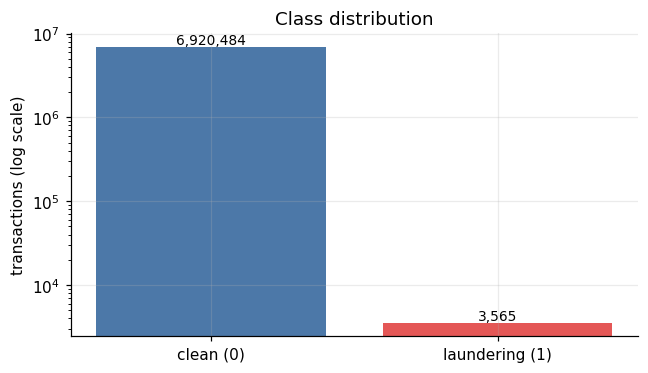

In [25]:
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(["clean (0)", "laundering (1)"], vc.reindex([0, 1]).fillna(0).values,
              color=["#4C78A8", "#E45756"])
ax.set_yscale("log")
ax.set_ylabel("transactions (log scale)")
ax.set_title("Class distribution")
for b, v in zip(bars, vc.reindex([0, 1]).fillna(0).values):
    ax.text(b.get_x() + b.get_width()/2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()

## 5. Transaction amounts

Amounts in AML data are heavy-tailed over several orders of magnitude, so everything is inspected on a
log scale. The `amount_paid` vs `amount_received` gap also encodes FX conversion — a useful signal,
since cross-currency legs are a common layering step.

In [26]:
amt = tx.loc[tx["amount_paid"] > 0, "amount_paid"]
qs  = [0.01, 0.25, 0.5, 0.75, 0.9, 0.99, 0.999, 0.9999]
summary = pd.DataFrame({
    "all":        amt.describe(),
})
print(summary.to_string())
print("\nquantiles:")
print(amt.quantile(qs).to_string())

                         all
count         6,924,049.0000
mean          4,676,035.9727
std       1,544,098,506.6939
min                   0.0000
25%                 175.3800
50%               1,399.4400
75%              12,226.8700
max   3,644,853,662,746.9502

quantiles:
0.0100               0.0100
0.2500             175.3800
0.5000           1,399.4400
0.7500          12,226.8700
0.9000         131,045.1300
0.9900      12,364,829.0200
0.9990     340,682,036.1116
0.9999   4,194,279,393.3300


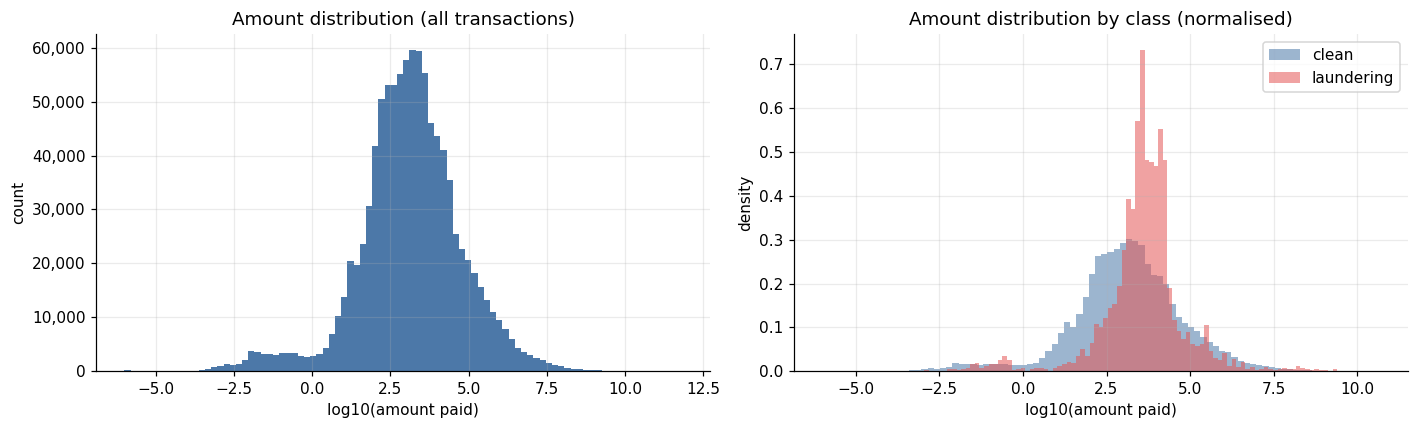

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].hist(np.log10(amt.sample(min(len(amt), 1_000_000), random_state=RANDOM_SEED)),
             bins=90, color="#4C78A8")
axes[0].set_xlabel("log10(amount paid)"); axes[0].set_ylabel("count")
axes[0].set_title("Amount distribution (all transactions)")
thousands(axes[0])

for lab, sub, col in [("clean", tx.loc[(tx.is_laundering == 0) & (tx.amount_paid > 0), "amount_paid"], "#4C78A8"),
                      ("laundering", tx.loc[(tx.is_laundering == 1) & (tx.amount_paid > 0), "amount_paid"], "#E45756")]:
    s = sub.sample(min(len(sub), 300_000), random_state=RANDOM_SEED)
    if len(s):
        axes[1].hist(np.log10(s), bins=90, density=True, alpha=0.55, label=lab, color=col)
axes[1].set_xlabel("log10(amount paid)"); axes[1].set_ylabel("density")
axes[1].set_title("Amount distribution by class (normalised)")
axes[1].legend()
plt.tight_layout(); plt.show()

In [28]:
if {"amount_paid", "amount_received"} <= set(tx.columns):
    fx = tx["amount_paid"].ne(tx["amount_received"])
    print(f"legs where paid != received (FX conversion): {fx.sum():,} ({fx.mean()*100:.2f}%)")
    print("\nlaundering rate by FX-conversion flag:")
    print((tx.groupby(fx)["is_laundering"].agg(["mean", "size"])
             .rename(columns={"mean": "laundering_rate", "size": "n"})
             .assign(laundering_rate=lambda d: (d.laundering_rate*100).round(4))).to_string())

legs where paid != received (FX conversion): 98,858 (1.43%)

laundering rate by FX-conversion flag:
       laundering_rate        n
False           0.0522  6825191
True            0.0000    98858


## 6. Categorical structure — payment rails, currencies, banks

The key view is not raw frequency but **laundering rate per category weighted by volume**. A rail with a
high rate but 12 transactions is noise; a rail with a moderate rate and 400k transactions is a control point.

In [29]:
def rate_by(col, min_n=50, top=20):
    if col not in tx.columns:
        print(f"(skipped: {col} not present)"); return None
    g = (tx.groupby(col, observed=True)["is_laundering"]
           .agg(n="size", n_laundering="sum", rate="mean"))
    g["rate_pct"] = (g["rate"] * 100).round(4)
    g["share_of_volume_pct"] = (g["n"] / len(tx) * 100).round(3)
    g = g[g["n"] >= min_n].drop(columns="rate")
    return g.sort_values("rate_pct", ascending=False).head(top)

pf = rate_by("payment_format")
pf

,n,n_laundering,rate_pct,share_of_volume_pct
payment_format,,,,
ACH,796581,2611,0.3278,11.5050
Bitcoin,309208,110,0.0356,4.4660
Cash,655688,124,0.0189,9.4700
Cheque,2503158,459,0.0183,36.1520
Credit Card,1780389,261,0.0147,25.7130
Reinvestment,650458,0,0.0000,9.3940
Wire,228567,0,0.0000,3.3010


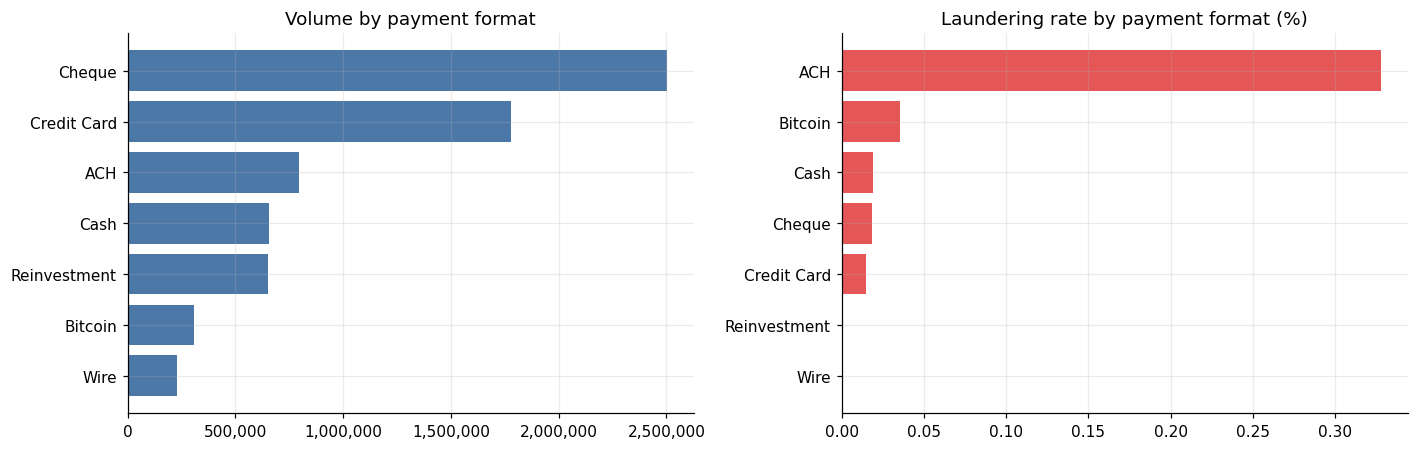

In [30]:
if pf is not None and len(pf):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
    order = pf.sort_values("n", ascending=True)
    axes[0].barh(order.index.astype(str), order["n"], color="#4C78A8")
    axes[0].set_title("Volume by payment format"); thousands(axes[0], "x")

    order2 = pf.sort_values("rate_pct", ascending=True)
    axes[1].barh(order2.index.astype(str), order2["rate_pct"], color="#E45756")
    axes[1].set_title("Laundering rate by payment format (%)")
    plt.tight_layout(); plt.show()

In [31]:
print("=== receiving currency ===")
display(rate_by("currency_received", top=15))

print("=== cross-border / cross-bank ===")
if {"from_bank", "to_bank"} <= set(tx.columns):
    tx["cross_bank"] = (tx["from_bank"].astype(str) != tx["to_bank"].astype(str))
    print((tx.groupby("cross_bank")["is_laundering"]
             .agg(n="size", rate="mean")
             .assign(rate_pct=lambda d: (d["rate"]*100).round(4))
             .drop(columns="rate")).to_string())

=== receiving currency ===


,n,n_laundering,rate_pct,share_of_volume_pct
currency_received,,,,
Euro,1596407,1025,0.0642,23.0560
US Dollar,2537242,1456,0.0574,36.6440
Canadian Dollar,177966,86,0.0483,2.5700
Saudi Riyal,261882,115,0.0439,3.7820
Ruble,89140,39,0.0438,1.2870
Mexican Peso,85374,37,0.0433,1.2330
UK Pound,98000,40,0.0408,1.4150
Yen,211631,86,0.0406,3.0560
Swiss Franc,140076,56,0.0400,2.0230


=== cross-border / cross-bank ===
                  n  rate_pct
cross_bank                   
False        912003    0.0080
True        6012046    0.0581


In [32]:
if {"currency_paid", "currency_received"} <= set(tx.columns):
    tx["currency_mismatch"] = (tx["currency_paid"].astype(str) != tx["currency_received"].astype(str))
    print("laundering rate by currency mismatch:")
    print((tx.groupby("currency_mismatch")["is_laundering"]
             .agg(n="size", rate="mean")
             .assign(rate_pct=lambda d: (d["rate"]*100).round(4))
             .drop(columns="rate")).to_string())

laundering rate by currency mismatch:
                         n  rate_pct
currency_mismatch                   
False              6825173    0.0522
True                 98876    0.0000


## 7. Temporal structure

Two things matter: (a) whether laundering is uniformly spread or clustered in campaigns, which dictates
**time-based train/test splitting**, and (b) burstiness at the account level, which is the raw material
for velocity features.

In [33]:
tx["date"]  = tx["timestamp"].dt.floor("D")
tx["hour"]  = tx["timestamp"].dt.hour
tx["dow"]   = tx["timestamp"].dt.dayofweek

print("date range:", tx["timestamp"].min(), "->", tx["timestamp"].max())
print("span      :", (tx["timestamp"].max() - tx["timestamp"].min()))
print("distinct days:", tx["date"].nunique())

date range: 2022-09-01 00:00:00 -> 2022-09-17 15:28:00
span      : 16 days 15:28:00
distinct days: 17


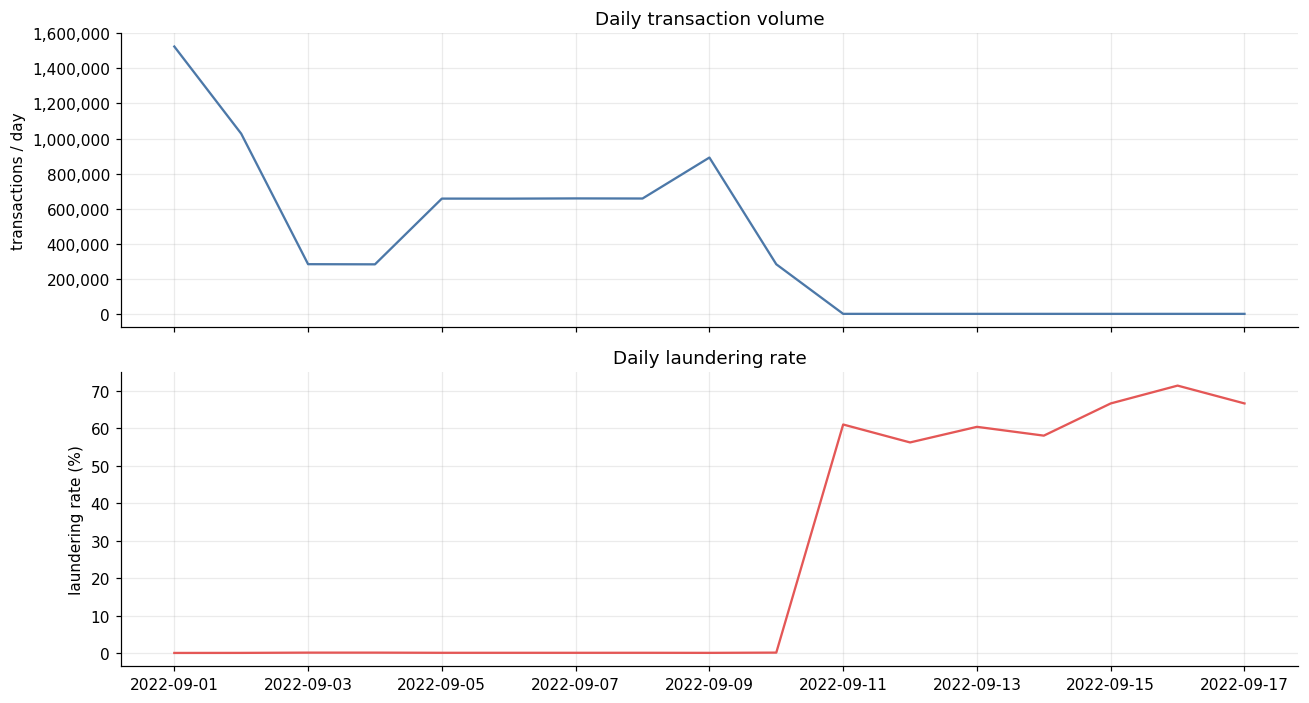

,n,n_laundering,rate_pct
count,17.0000,17.0000,17.0000
mean,"407,297.0000",209.7059,25.9512
std,"455,982.4420",167.4682,32.0678
min,3.0000,2.0000,0.0203
25%,48.0000,27.0000,0.0563
50%,"282,877.0000",292.0000,0.1031
75%,"657,938.0000",367.0000,60.4167
max,"1,524,807.0000",402.0000,71.4286


In [34]:
daily = tx.groupby("date").agg(n=("is_laundering", "size"),
                               n_laundering=("is_laundering", "sum"))
daily["rate_pct"] = daily["n_laundering"] / daily["n"] * 100

fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
axes[0].plot(daily.index, daily["n"], color="#4C78A8")
axes[0].set_ylabel("transactions / day"); axes[0].set_title("Daily transaction volume")
thousands(axes[0])
axes[1].plot(daily.index, daily["rate_pct"], color="#E45756")
axes[1].set_ylabel("laundering rate (%)"); axes[1].set_title("Daily laundering rate")
plt.tight_layout(); plt.show()

display(daily.describe())

> If the daily volume plot shows a sharp ramp at the start or a cliff at the end, those are simulator
> warm-up/cool-down artefacts. Trim them before splitting, or the model learns the boundary instead of
> the behaviour.

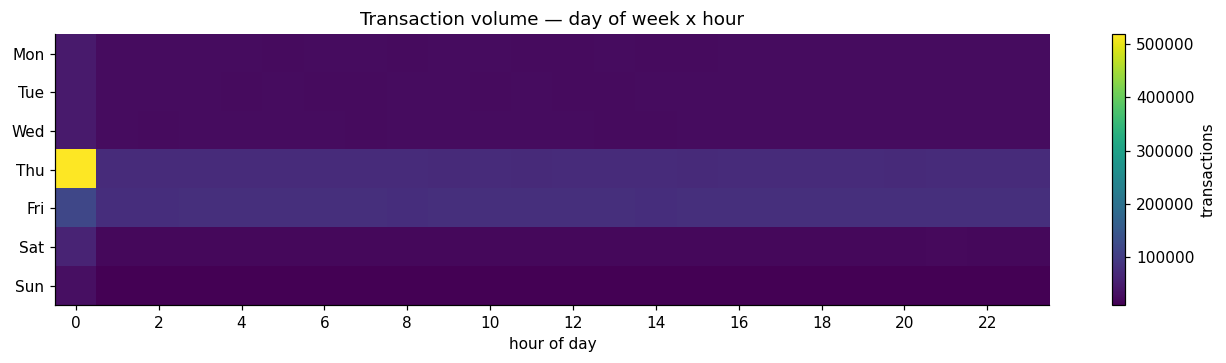

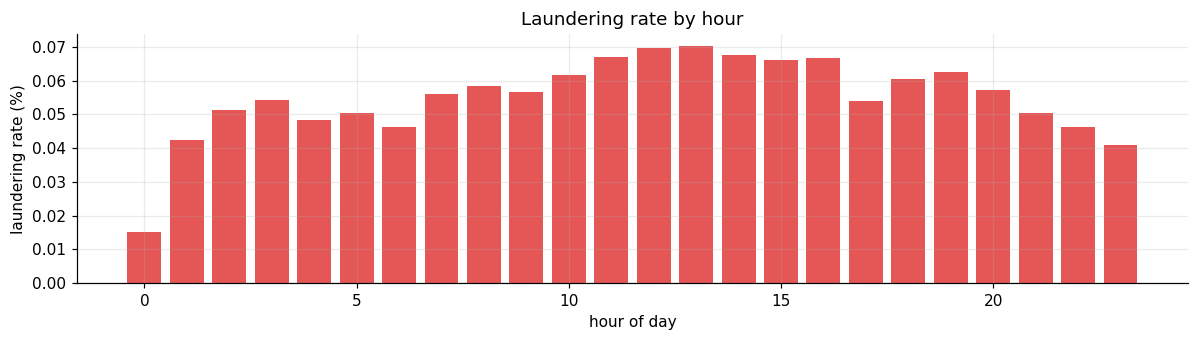

In [35]:
pivot = (tx.pivot_table(index="dow", columns="hour", values="is_laundering",
                        aggfunc="size", observed=True)
           .reindex(range(7)))
fig, ax = plt.subplots(figsize=(12, 3.4))
im = ax.imshow(pivot.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(7), ["Mon","Tue","Wed","Thu","Fri","Sat","Sun"])
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel("hour of day")
ax.set_title("Transaction volume — day of week x hour")
ax.grid(False); plt.colorbar(im, ax=ax, label="transactions")
plt.tight_layout(); plt.show()

hourly = (tx.groupby("hour")["is_laundering"].mean() * 100)
fig, ax = plt.subplots(figsize=(11, 3.2))
ax.bar(hourly.index, hourly.values, color="#E45756")
ax.set_xlabel("hour of day"); ax.set_ylabel("laundering rate (%)")
ax.set_title("Laundering rate by hour")
plt.tight_layout(); plt.show()

### 7.1 Burstiness

Rapid-fire transfers from a single account are a core structuring signal. Here we measure the median
inter-transaction gap per sending account and compare flagged vs clean accounts.

                median_gap_min  min_gap_min  n_sent
ever_laundered                                     
0                     735.0000     266.0000  2.0000
1                     961.0000       5.0000  3.0000


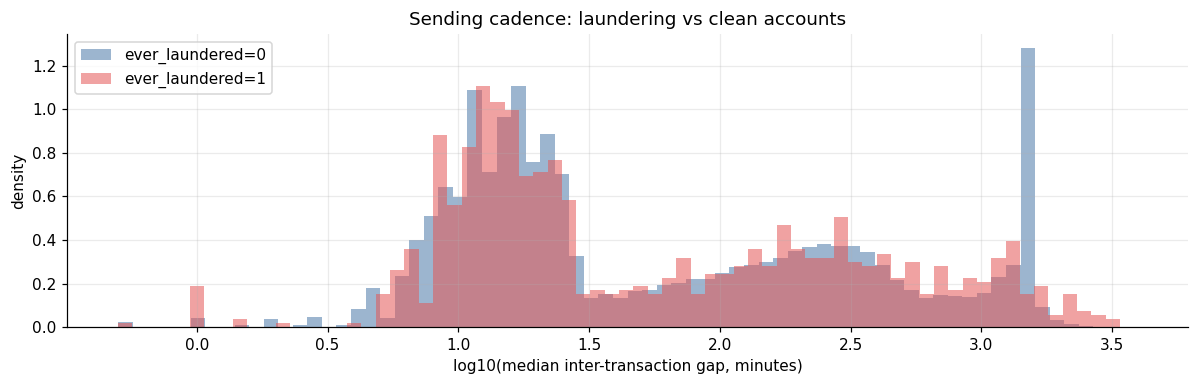

21755

In [36]:
tx_sorted = tx[["from_account", "timestamp", "is_laundering"]].sort_values(["from_account", "timestamp"])
tx_sorted["gap_min"] = (tx_sorted.groupby("from_account", observed=True)["timestamp"]
                                 .diff().dt.total_seconds() / 60)

gap_stats = (tx_sorted.dropna(subset=["gap_min"])
             .groupby("from_account", observed=True)
             .agg(median_gap_min=("gap_min", "median"),
                  min_gap_min=("gap_min", "min"),
                  n_sent=("gap_min", "size"),
                  ever_laundered=("is_laundering", "max")))

print(gap_stats.groupby("ever_laundered")[["median_gap_min", "min_gap_min", "n_sent"]]
      .median().to_string())

burst = gap_stats[gap_stats["n_sent"] >= 5]
fig, ax = plt.subplots(figsize=(11, 3.6))
for lab, col in [(0, "#4C78A8"), (1, "#E45756")]:
    s = burst.loc[burst.ever_laundered == lab, "median_gap_min"]
    s = s[s > 0]
    if len(s):
        ax.hist(np.log10(s), bins=70, density=True, alpha=0.55,
                label=f"ever_laundered={lab}", color=col)
ax.set_xlabel("log10(median inter-transaction gap, minutes)"); ax.set_ylabel("density")
ax.set_title("Sending cadence: laundering vs clean accounts"); ax.legend()
plt.tight_layout(); plt.show()

del tx_sorted; gc.collect()

## 8. Account-level aggregation

Collapse the edge list into a node feature table: degree, volume, net flow, counterparty diversity.
This table is the bridge between transaction-level EDA and the graph section — and is reusable directly
as GNN node features.

In [37]:
out_agg = (tx.groupby("from_account", observed=True)
             .agg(out_degree=("to_account", "size"),
                  out_unique=("to_account", "nunique"),
                  out_amount=("amount_paid", "sum"),
                  out_amount_mean=("amount_paid", "mean"),
                  out_amount_std=("amount_paid", "std"),
                  out_laundering=("is_laundering", "sum"))
             .rename_axis("account_id"))

in_agg = (tx.groupby("to_account", observed=True)
            .agg(in_degree=("from_account", "size"),
                 in_unique=("from_account", "nunique"),
                 in_amount=("amount_received", "sum") if "amount_received" in tx else ("amount_paid", "sum"),
                 in_amount_mean=("amount_paid", "mean"),
                 in_laundering=("is_laundering", "sum"))
            .rename_axis("account_id"))

nodes = out_agg.join(in_agg, how="outer").fillna(0)
nodes["degree"]      = nodes["in_degree"] + nodes["out_degree"]
nodes["net_flow"]    = nodes["in_amount"] - nodes["out_amount"]
nodes["flow_ratio"]  = nodes["out_amount"] / nodes["in_amount"].replace(0, np.nan)
nodes["fan_in"]      = nodes["in_unique"]
nodes["fan_out"]     = nodes["out_unique"]
nodes["fan_ratio"]   = nodes["fan_out"] / nodes["fan_in"].replace(0, np.nan)
nodes["is_laundering_node"] = ((nodes["in_laundering"] + nodes["out_laundering"]) > 0).astype("int8")

print(f"node table: {nodes.shape[0]:,} accounts x {nodes.shape[1]} features")
print(f"accounts touching >=1 laundering txn: {nodes['is_laundering_node'].sum():,} "
      f"({nodes['is_laundering_node'].mean()*100:.3f}%)")
nodes.head()

node table: 705,903 accounts x 18 features
accounts touching >=1 laundering txn: 5,304 (0.751%)


,out_degree,out_unique,out_amount,out_amount_mean,out_amount_std,out_laundering,in_degree,in_unique,in_amount,in_amount_mean,in_laundering,degree,net_flow,flow_ratio,fan_in,fan_out,fan_ratio,is_laundering_node
account_id,,,,,,,,,,,,,,,,,,
10042B660,"222,037.0000","18,942.0000","73,113,736,651.5400","329,286.2750","12,410,256.6152",314.0000,"1,553.0000",785.0000,"803,053.5000",517.0982,0.0000,"223,590.0000","-73,112,933,598.0400","91,044.6647",785.0000,"18,942.0000",24.1299,1
10042B6A8,"138,777.0000","11,877.0000","37,451,441,299.4600","269,867.7828","6,074,104.2692",196.0000,951.0000,478.0000,"414,927.1800",436.3062,0.0000,"139,728.0000","-37,451,026,372.2800","90,260.2748",478.0000,"11,877.0000",24.8473,1
10042B6F0,"42,385.0000","3,611.0000","105,904,323,562.0100","2,498,627.4286","71,323,439.0905",48.0000,345.0000,176.0000,"1,421,533.4500","4,120.3868",0.0000,"42,730.0000","-105,902,902,028.5600","74,500.0574",176.0000,"3,611.0000",20.5170,1
10042B738,"18,213.0000","1,560.0000","924,295,797,491.3800","50,749,233.9258","2,523,946,981.5094",28.0000,135.0000,70.0000,"6,197,232.2900","45,905.4244",0.0000,"18,348.0000","-924,289,600,259.0900","149,146.5471",70.0000,"1,560.0000",22.2857,1
10042B780,"30,802.0000","2,620.0000","729,181,092,474.4399","23,673,173.5756","436,771,939.1907",32.0000,223.0000,118.0000,"6,788,354.4200","30,441.0512",0.0000,"31,025.0000","-729,174,304,120.0199","107,416.4735",118.0000,"2,620.0000",22.2034,1


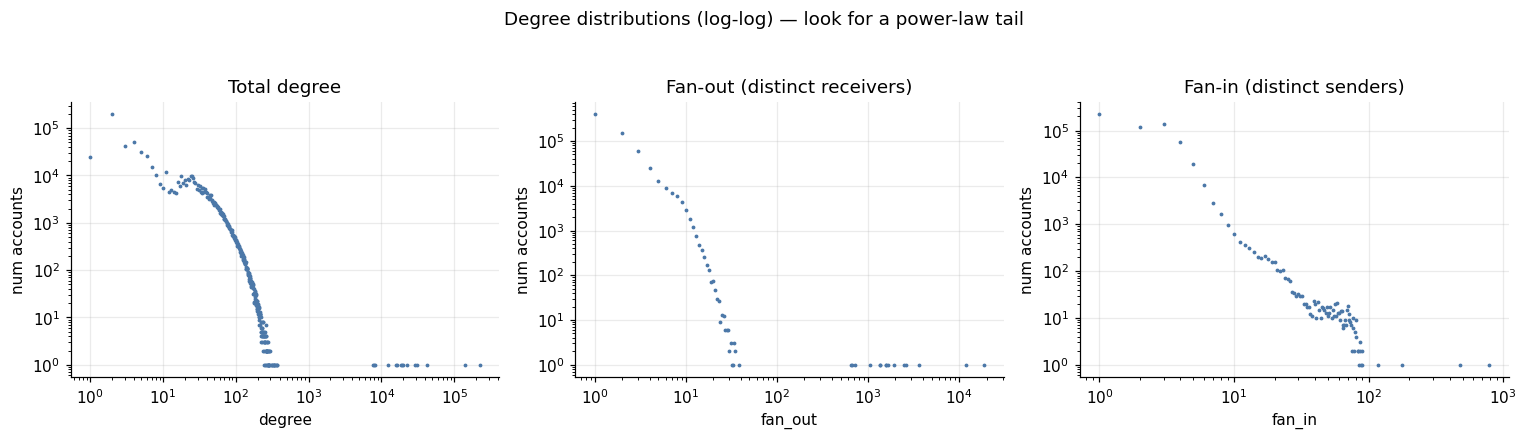

Top 10 fan-out accounts (potential distributors):


,fan_out,fan_in,out_amount,is_laundering_node
account_id,,,,
10042B660,"18,942.0000",785.0000,"73,113,736,651.5400",1
10042B6A8,"11,877.0000",478.0000,"37,451,441,299.4600",1
10042B6F0,"3,611.0000",176.0000,"105,904,323,562.0100",1
10042B780,"2,620.0000",118.0000,"729,181,092,474.4399",1
10042BA51,"2,474.0000",42.0000,"762,910.6619",1
10042BA08,"1,928.0000",86.0000,"23,318,839,990.6300",1
10042B8A0,"1,637.0000",81.0000,"9,356,174,980.5600",1
10042B930,"1,594.0000",67.0000,"28,700,687,549.9500",1
10042B738,"1,560.0000",70.0000,"924,295,797,491.3800",1


Top 10 fan-in accounts (potential collectors / mules):


,fan_in,fan_out,in_amount,is_laundering_node
account_id,,,,
10042B660,785.0000,"18,942.0000","803,053.5000",1
10042B6A8,478.0000,"11,877.0000","414,927.1800",1
10042B6F0,176.0000,"3,611.0000","1,421,533.4500",1
10042B780,118.0000,"2,620.0000","6,788,354.4200",1
808283270,90.0000,2.0000,"9,129,985.8000",0
80AC3D4E0,90.0000,0.0000,"44,314,373.2500",0
818923590,89.0000,2.0000,"871,846.5900",0
80AEBC5F0,88.0000,1.0000,"6,908,260.7000",0
805ADEA90,87.0000,1.0000,"13,367,492.2700",0


In [38]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, col, title in zip(axes,
                          ["degree", "fan_out", "fan_in"],
                          ["Total degree", "Fan-out (distinct receivers)", "Fan-in (distinct senders)"]):
    s = nodes[col]; s = s[s > 0]
    counts = s.value_counts().sort_index()
    ax.loglog(counts.index, counts.values, ".", markersize=3, color="#4C78A8")
    ax.set_xlabel(col); ax.set_ylabel("num accounts"); ax.set_title(title)
plt.suptitle("Degree distributions (log-log) — look for a power-law tail", y=1.04)
plt.tight_layout(); plt.show()

print("Top 10 fan-out accounts (potential distributors):")
display(nodes.nlargest(10, "fan_out")[["fan_out", "fan_in", "out_amount", "is_laundering_node"]])

print("Top 10 fan-in accounts (potential collectors / mules):")
display(nodes.nlargest(10, "fan_in")[["fan_in", "fan_out", "in_amount", "is_laundering_node"]])

## 9. Network graph analysis

Built with NetworkX on a capped edge sample. For the full LI-Small graph in production, swap to
`graph-tool`, `cuGraph` or PyTorch Geometric — NetworkX will not scale to millions of edges for
PageRank and cycle enumeration.

In [39]:
try:
    import networkx as nx
    HAS_NX = True
except ImportError:
    HAS_NX = False
    print("networkx not installed — run: pip install networkx")

In [40]:
if HAS_NX:
    edges = tx[["from_account", "to_account", "amount_paid", "is_laundering"]]
    if len(edges) > GRAPH_SAMPLE_EDGES:
        # keep ALL laundering edges + random sample of clean ones (preserves signal)
        pos = edges[edges.is_laundering == 1]
        neg = edges[edges.is_laundering == 0].sample(
            max(GRAPH_SAMPLE_EDGES - len(pos), 0), random_state=RANDOM_SEED)
        edges = pd.concat([pos, neg])
        print(f"sampled graph: {len(edges):,} edges ({len(pos):,} laundering kept in full)")

    G = nx.from_pandas_edgelist(edges, "from_account", "to_account",
                                edge_attr=["amount_paid", "is_laundering"],
                                create_using=nx.DiGraph())
    print(f"nodes: {G.number_of_nodes():,}  edges: {G.number_of_edges():,}")
    print(f"density: {nx.density(G):.8f}")

sampled graph: 500,000 edges (3,565 laundering kept in full)
nodes: 322,898  edges: 328,087
density: 0.00000315


In [41]:
if HAS_NX:
    wcc = list(nx.weakly_connected_components(G))
    sizes = pd.Series([len(c) for c in wcc]).sort_values(ascending=False)
    print(f"weakly connected components: {len(wcc):,}")
    print(f"largest component: {sizes.iloc[0]:,} nodes "
          f"({sizes.iloc[0]/G.number_of_nodes()*100:.1f}% of graph)")
    print("\ncomponent size distribution:")
    print(sizes.describe().to_string())
    print("\ntop 10 component sizes:", list(sizes.head(10)))

weakly connected components: 64,168
largest component: 193,911 nodes (60.1% of graph)

component size distribution:
count    64,168.0000
mean          5.0321
std         765.4901
min           1.0000
25%           1.0000
50%           2.0000
75%           2.0000
max     193,911.0000

top 10 component sizes: [193911, 44, 37, 32, 31, 29, 28, 28, 28, 28]


In [42]:
if HAS_NX:
    pr = nx.pagerank(G, alpha=0.85, max_iter=60, tol=1e-6)
    pr_s = pd.Series(pr, name="pagerank")

    lnd_nodes = set(edges.loc[edges.is_laundering == 1, "from_account"]) | \
                set(edges.loc[edges.is_laundering == 1, "to_account"])
    flag = pr_s.index.isin(lnd_nodes)

    print("median PageRank — laundering-linked vs clean:")
    print(f"  laundering-linked: {pr_s[flag].median():.3e}  (n={flag.sum():,})")
    print(f"  clean            : {pr_s[~flag].median():.3e}  (n={(~flag).sum():,})")

    print("\nTop 15 accounts by PageRank:")
    top_pr = pr_s.nlargest(15).to_frame()
    top_pr["laundering_linked"] = top_pr.index.isin(lnd_nodes)
    display(top_pr)

median PageRank — laundering-linked vs clean:
  laundering-linked: 2.647e-06  (n=5,304)
  clean            : 2.657e-06  (n=317,594)

Top 15 accounts by PageRank:


,pagerank,laundering_linked
10042B660,0.0001,True
10042B6A8,0.0001,True
806DFE960,0.0000,False
8144DAE90,0.0000,False
81633C5C0,0.0000,False
80B2D6CC0,0.0000,False
8029E8CF0,0.0000,True
803049310,0.0000,False
814C353A0,0.0000,False
8122A8160,0.0000,False


### 9.1 Cycle detection (layering signature)

Circular flows `A -> B -> C -> A` return funds to origin through intermediaries. Enumerating all cycles
is exponential, so this bounds the search to short cycles on the laundering-linked subgraph.

laundering-linked subgraph: 5,304 nodes, 4,291 edges
cycles found (len<=6, capped at 3000): 589

cycle length distribution:
1    546
2     34
3      3
4      3
5      2
6      1


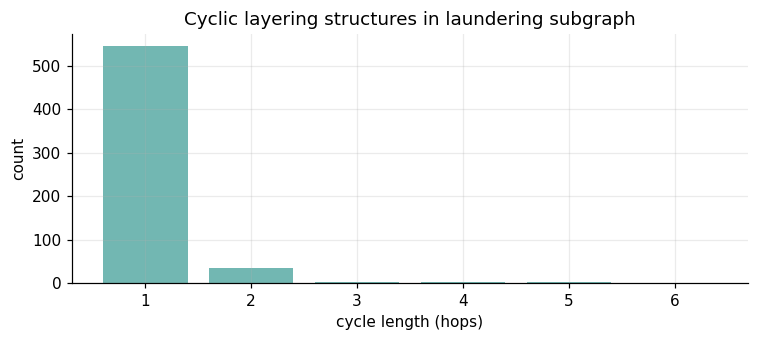


example 3-hop cycles: [['8016EA8A0', '8018CF810', '800AF7050'], ['8023BE570', '80220D0A0', '802BC3160'], ['80267BC80', '8017AD1A0', '8003B1FD0']]


In [43]:
if HAS_NX:
    sub = G.subgraph(lnd_nodes).copy()
    print(f"laundering-linked subgraph: {sub.number_of_nodes():,} nodes, {sub.number_of_edges():,} edges")

    cycles, MAX_CYCLES, MAX_LEN = [], 3000, 6
    try:
        for cyc in nx.simple_cycles(sub, length_bound=MAX_LEN):   # networkx >= 3.1
            cycles.append(cyc)
            if len(cycles) >= MAX_CYCLES:
                break
    except TypeError:
        for cyc in nx.simple_cycles(sub):
            if len(cyc) <= MAX_LEN:
                cycles.append(cyc)
            if len(cycles) >= MAX_CYCLES:
                break

    print(f"cycles found (len<={MAX_LEN}, capped at {MAX_CYCLES}): {len(cycles):,}")
    if cycles:
        lens = pd.Series([len(c) for c in cycles]).value_counts().sort_index()
        print("\ncycle length distribution:")
        print(lens.to_string())
        fig, ax = plt.subplots(figsize=(7, 3.2))
        ax.bar(lens.index.astype(str), lens.values, color="#72B7B2")
        ax.set_xlabel("cycle length (hops)"); ax.set_ylabel("count")
        ax.set_title("Cyclic layering structures in laundering subgraph")
        plt.tight_layout(); plt.show()
        print("\nexample 3-hop cycles:", [c for c in cycles if len(c) == 3][:3])

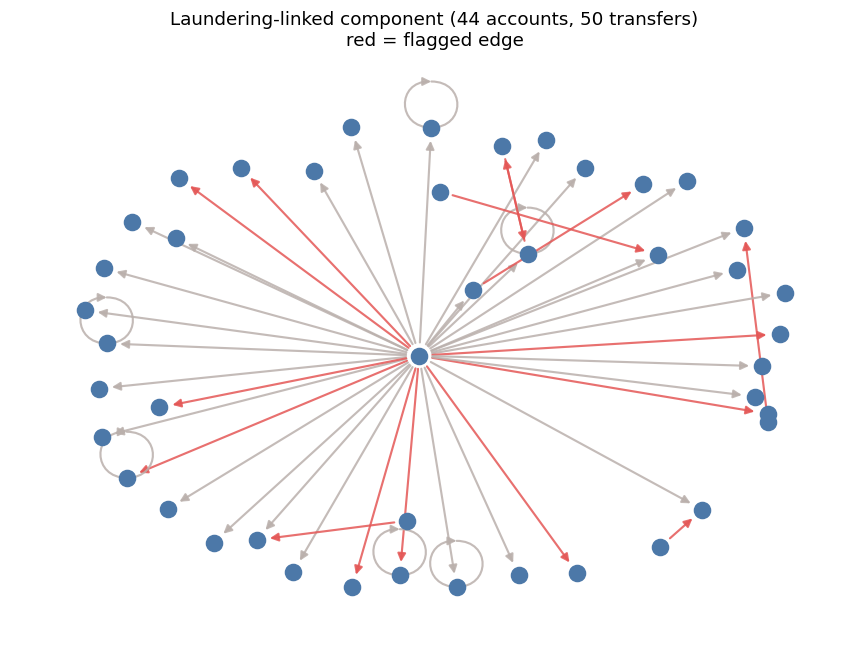

In [44]:
if HAS_NX and len(lnd_nodes) > 2:
    # Visualise one laundering component
    lnd_sub = G.subgraph(lnd_nodes)
    comps = sorted(nx.weakly_connected_components(lnd_sub), key=len, reverse=True)
    target = [c for c in comps if 6 <= len(c) <= 45]
    if target:
        H = lnd_sub.subgraph(target[0])
        pos_layout = nx.spring_layout(H, seed=RANDOM_SEED, k=0.7)
        ecol = ["#E45756" if d["is_laundering"] == 1 else "#BAB0AC" for *_, d in H.edges(data=True)]
        fig, ax = plt.subplots(figsize=(8, 6))
        nx.draw_networkx_nodes(H, pos_layout, node_size=110, node_color="#4C78A8", ax=ax)
        nx.draw_networkx_edges(H, pos_layout, edge_color=ecol, width=1.4,
                               arrowsize=11, alpha=0.85, ax=ax)
        ax.set_title(f"Laundering-linked component ({H.number_of_nodes()} accounts, "
                     f"{H.number_of_edges()} transfers)\nred = flagged edge")
        ax.axis("off"); ax.grid(False)
        plt.tight_layout(); plt.show()
    else:
        print("no laundering component in the 6–45 node range to plot")

## 10. Structuring / smurfing — threshold proximity

Structuring means splitting a large sum into transfers that each sit just under a mandatory reporting
threshold (commonly $10,000 in US CTR terms). The test: is there an anomalous mass of transactions in
the band just *below* a round threshold, relative to the band just above it?

The structuring check compares `amount_paid` against a literal $10,000. That number is a regulatory concept denominated in USD. Amount columns will have to be converted to dollars.

In [45]:
THRESHOLDS = [10_000, 5_000, 3_000]
BAND = 0.15   # +/- 15% window around each threshold

rows = []
for t in THRESHOLDS:
    lo, hi = t * (1 - BAND), t * (1 + BAND)
    below = tx[(tx.amount_paid >= lo) & (tx.amount_paid < t)]
    above = tx[(tx.amount_paid >= t) & (tx.amount_paid <= hi)]
    rows.append({
        "threshold": t,
        "n_just_below": len(below),
        "n_just_above": len(above),
        "below_above_ratio": len(below) / max(len(above), 1),
        "laundering_rate_below_pct": below["is_laundering"].mean() * 100 if len(below) else np.nan,
        "laundering_rate_above_pct": above["is_laundering"].mean() * 100 if len(above) else np.nan,
    })

structuring = pd.DataFrame(rows)
display(structuring)
print("A below/above ratio meaningfully > 1 is evidence of deliberate structuring.")

,threshold,n_just_below,n_just_above,below_above_ratio,laundering_rate_below_pct,laundering_rate_above_pct
0,10000,107519,93071,1.1552,0.1144,0.0935
1,5000,130433,101785,1.2815,0.1296,0.0717
2,3000,146167,121415,1.2039,0.1060,0.1120


A below/above ratio meaningfully > 1 is evidence of deliberate structuring.


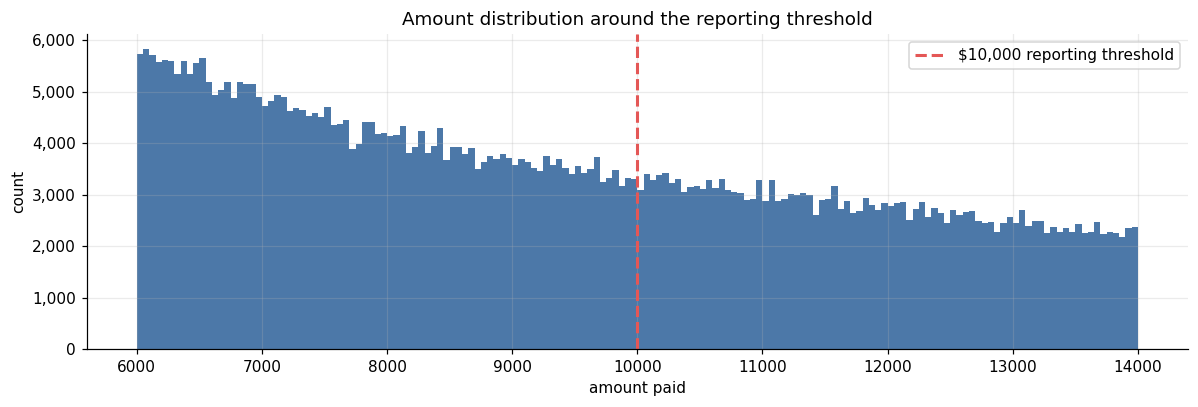

In [46]:
zoom = tx.loc[tx.amount_paid.between(6_000, 14_000), "amount_paid"]
if len(zoom):
    fig, ax = plt.subplots(figsize=(11, 3.8))
    ax.hist(zoom, bins=160, color="#4C78A8")
    ax.axvline(10_000, color="#E45756", ls="--", lw=2, label="$10,000 reporting threshold")
    ax.set_xlabel("amount paid"); ax.set_ylabel("count")
    ax.set_title("Amount distribution around the reporting threshold")
    ax.legend(); thousands(ax)
    plt.tight_layout(); plt.show()
else:
    print("no transactions in the 6k–14k band (check dataset currency scale)")

In [47]:
# Round-number clustering: laundering often uses suspiciously tidy amounts
tx["is_round_1k"] = (tx["amount_paid"] % 1000 == 0)
tx["is_round_100"] = (tx["amount_paid"] % 100 == 0)
print((tx.groupby("is_round_1k")["is_laundering"]
         .agg(n="size", rate="mean")
         .assign(rate_pct=lambda d: (d["rate"]*100).round(4))
         .drop(columns="rate")).to_string())

                   n  rate_pct
is_round_1k                   
False        6924008    0.0515
True              41    0.0000


## 11. Profiling: laundering vs clean accounts

Side-by-side comparison of the node features. Anything with a large ratio between the two groups is a
candidate feature; anything near 1.0 is not worth the compute.

In [48]:
feat_cols = ["degree", "in_degree", "out_degree", "fan_in", "fan_out", "fan_ratio",
             "in_amount", "out_amount", "out_amount_mean", "out_amount_std",
             "net_flow", "flow_ratio"]

comp = (nodes.groupby("is_laundering_node")[feat_cols]
             .median().T
             .rename(columns={0: "clean_median", 1: "laundering_median"}))
comp["ratio"] = comp["laundering_median"] / comp["clean_median"].replace(0, np.nan)
comp = comp.sort_values("ratio", ascending=False)
display(comp)

is_laundering_node,clean_median,laundering_median,ratio
out_amount_std,64.6437,"9,777.1838",151.2473
out_amount,"10,003.6100","86,497.0050",8.6466
in_amount,"13,243.4700","107,075.6900",8.0852
in_degree,2.0000,12.0000,6.0000
degree,6.0000,22.0000,3.6667
fan_in,1.0000,3.0000,3.0000
out_amount_mean,"3,559.4400","9,987.7162",2.8060
fan_out,1.0000,2.0000,2.0000
out_degree,2.0000,3.0000,1.5000
flow_ratio,1.0000,0.9796,0.9796


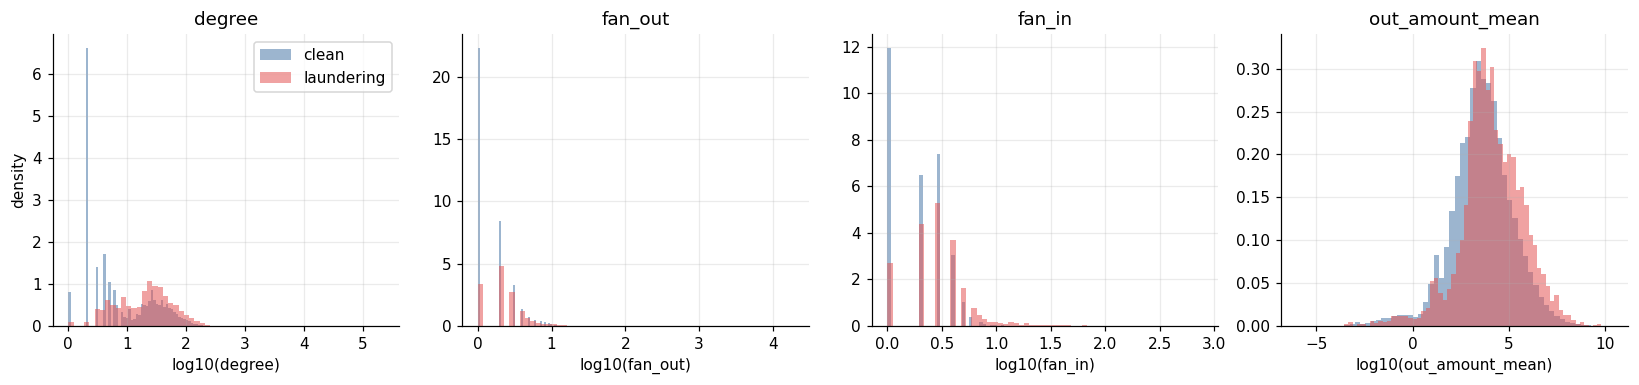

In [49]:
plot_cols = ["degree", "fan_out", "fan_in", "out_amount_mean"]
fig, axes = plt.subplots(1, len(plot_cols), figsize=(15, 3.6))
for ax, col in zip(axes, plot_cols):
    for lab, c in [(0, "#4C78A8"), (1, "#E45756")]:
        s = nodes.loc[nodes.is_laundering_node == lab, col]
        s = s[s > 0]
        if len(s):
            ax.hist(np.log10(s.sample(min(len(s), 200_000), random_state=RANDOM_SEED)),
                    bins=60, density=True, alpha=0.55, color=c,
                    label={0: "clean", 1: "laundering"}[lab])
    ax.set_title(col); ax.set_xlabel(f"log10({col})")
axes[0].set_ylabel("density"); axes[0].legend()
plt.tight_layout(); plt.show()

In [50]:
if acc is not None:
    joined = nodes.join(acc.drop_duplicates("account_id").set_index("account_id"), how="left")
    for col in ("account_type", "bank_id", "country"):
        if col in joined.columns and joined[col].notna().any():
            g = (joined.groupby(col, observed=True)["is_laundering_node"]
                       .agg(n="size", rate="mean")
                       .assign(rate_pct=lambda d: (d["rate"]*100).round(3))
                       .drop(columns="rate")
                       .query("n >= 30")
                       .sort_values("rate_pct", ascending=False))
            print(f"\n=== laundering-account rate by {col} (top 15) ===")
            display(g.head(15))
else:
    print("accounts file not loaded — node-metadata breakdown skipped")


=== laundering-account rate by bank_id (top 15) ===


,n,rate_pct
bank_id,,
Willows Thrift,100,15.0000
China Bank #909,44,6.8180
Australia Bank #171,38,5.2630
Australia Bank #85,38,5.2630
Japan Bank #280,106,4.7170
Brazil Bank #60,108,4.6300
Crytpo Bank #57,65,4.6150
Germany Bank #2481,48,4.1670
Canada Bank #56,76,3.9470


## 12. Findings, artefacts & next steps

In [51]:
findings = {
    "n_transactions":        int(len(tx)),
    "n_accounts_active":     int(len(nodes)),
    "n_accounts_metadata":   int(len(acc)) if acc is not None else None,
    "date_range":            f"{tx.timestamp.min()} .. {tx.timestamp.max()}",
    "positive_rate_pct":     round(float(tx.is_laundering.mean() * 100), 5),
    "imbalance_ratio":       int(round((tx.is_laundering == 0).sum() / max((tx.is_laundering == 1).sum(), 1))),
    "laundering_account_pct": round(float(nodes.is_laundering_node.mean() * 100), 4),
    "self_loops":            int(self_loops),
    "duplicate_rows":        int(dupes),
}
for k, v in findings.items():
    print(f"{k:24s}: {v}")

pd.Series(findings).to_json(OUT_DIR / "eda_summary.json", indent=2)

# Persist the node feature table — this is the input to Step 3 (feature engineering)
nodes.reset_index().to_csv(OUT_DIR / "account_features.csv", index=False)
print(f"\nsaved -> {OUT_DIR/'account_features.csv'}  ({nodes.shape[0]:,} rows)")
print(f"saved -> {OUT_DIR/'eda_summary.json'}")

n_transactions          : 6924049
n_accounts_active       : 705903
n_accounts_metadata     : 712688
date_range              : 2022-09-01 00:00:00 .. 2022-09-17 15:28:00
positive_rate_pct       : 0.05149
imbalance_ratio         : 1941
laundering_account_pct  : 0.7514
self_loops              : 804477
duplicate_rows          : 8

saved -> eda_output/account_features.csv  (705,903 rows)
saved -> eda_output/eda_summary.json


### What this EDA implies for modelling

1. **Split by time, not at random.** Transactions share accounts; a random split leaks an account's future
   behaviour into its own training rows. Use a temporal cut, and drop simulator warm-up/cool-down days.
2. **Never optimise accuracy or plain ROC-AUC.** At this positive rate, use PR-AUC, recall at a fixed
   alert budget (e.g. recall@1000 alerts/day), and calibrate the threshold to investigator capacity.
3. **Resample inside the fold only.** SMOTE or undersampling applied before splitting inflates every
   metric. Prefer `scale_pos_weight` / focal loss over synthetic oversampling for graph-derived features.
4. **Graph features are the differentiator.** The fan-in/fan-out and PageRank gaps in Section 11 are what
   tabular-only models cannot recover; feed them into XGBoost, or go straight to an RGCN/GAT edge classifier.
5. **Label semantics.** `Is Laundering` is an *edge* label. Node-level labels here are derived
   (`is_laundering_node`) and are weaker — be explicit about which task you are training.
6. **Keep the orphan/dormant accounts in mind.** Dormant accounts in `LI-Small_accounts.csv` carry no edges
   and will get zero-valued graph features; that zero is a real signal, not a missing value.

### Next steps
- Build rolling-window velocity features (24h / 7d / 30d) per account.
- Motif counting: fan-in/fan-out stars, scatter-gather, and the cycles found in Section 9.1.
- Move the graph work to PyTorch Geometric and train an edge-classification GNN as the Tier-2 model.

In [67]:
import networkx as nx

BITCOIN = 'Bitcoin'
MIN_N   = 30   # below this, a direct pair rate isn't trusted; chain or fall back instead

# ============================================================
# STEP 1 — implied rate from every cross-currency leg
# ============================================================
fx = tx.loc[tx['currency_paid'] != tx['currency_received'],
            ['currency_paid', 'currency_received', 'amount_paid', 'amount_received', 'timestamp']].copy()
fx['implied_rate'] = fx['amount_received'] / fx['amount_paid']
fx['date'] = fx['timestamp'].dt.floor('D')

pair_rates = (fx.groupby(['currency_paid', 'currency_received'], observed=True)['implied_rate']
                .agg(median='median', std='std', n='count'))
pair_rates['cv'] = pair_rates['std'] / pair_rates['median']
pair_rates = pair_rates.sort_values('n', ascending=False)
print(f"real pairs observed: {len(pair_rates):,} / 210 possible")

is_btc_pair = (pair_rates.index.get_level_values('currency_paid') == BITCOIN) | \
              (pair_rates.index.get_level_values('currency_received') == BITCOIN)
fiat_pairs = pair_rates[~is_btc_pair]

unstable = fiat_pairs[fiat_pairs['cv'] > 0.05]
if len(unstable):
    print(f"\n{len(unstable)} fiat pairs with cv > 0.05 (noise, usually low n — the two-tier "
          f"fallback below routes around these):")
    print(unstable)

# ============================================================
# STEP 2 — two-tier fiat -> USD graph
#   Tier 1: only pairs with enough observations to trust directly (n >= MIN_N)
#   Tier 2 (fallback): any observed pair at all, used only where Tier 1 has no path
# ============================================================
def build_graph(pairs_df):
    G = nx.DiGraph()
    for (src, dst), row in pairs_df.iterrows():
        G.add_edge(src, dst, rate=row['median'])
        if not G.has_edge(dst, src):
            G.add_edge(dst, src, rate=1 / row['median'])
    return G

def rate_via_graph(G, cur, target='US Dollar'):
    if not (G.has_node(cur) and nx.has_path(G, cur, target)):
        return None
    path = nx.shortest_path(G, cur, target)
    rate = 1.0
    for a, b in zip(path[:-1], path[1:]):
        rate *= G[a][b]['rate']
    return rate

reliable_fiat = fiat_pairs[fiat_pairs['n'] >= MIN_N]
G_reliable = build_graph(reliable_fiat)
G_all      = build_graph(fiat_pairs)   # fallback: every pair, however thin

fiat_currencies = [c for c in tx['currency_paid'].cat.categories if c != BITCOIN]
usd_rate, rate_source = {'US Dollar': 1.0}, {'US Dollar': 'base'}
for cur in fiat_currencies:
    if cur == 'US Dollar':
        continue
    r = rate_via_graph(G_reliable, cur)
    if r is not None:
        usd_rate[cur], rate_source[cur] = r, 'reliable'
        continue
    r = rate_via_graph(G_all, cur)
    if r is not None:
        usd_rate[cur], rate_source[cur] = r, 'fallback(thin)'
    else:
        rate_source[cur] = 'NO PATH — needs an external rate'

rate_report = pd.DataFrame({'usd_rate': pd.Series(usd_rate), 'source': pd.Series(rate_source)})
print("\nfiat -> USD rates:")
print(rate_report)
no_path = [c for c, s in rate_source.items() if 'NO PATH' in s]
if no_path:
    print(f"\n!! no rate found for: {no_path} — supply an external rate for these before proceeding")

# ============================================================
# STEP 3 — Bitcoin gets its OWN per-day rate, pooled across every
# fiat counter-currency (converted to USD first via usd_rate above),
# because it's genuinely volatile, not just thinly sampled
# ============================================================
btc_legs = fx[(fx.currency_paid == BITCOIN) | (fx.currency_received == BITCOIN)].copy()

def implied_btc_usd(row):
    if row['currency_paid'] == BITCOIN and row['currency_received'] in usd_rate:
        return (row['amount_received'] * usd_rate[row['currency_received']]) / row['amount_paid']
    if row['currency_received'] == BITCOIN and row['currency_paid'] in usd_rate:
        return (row['amount_paid'] * usd_rate[row['currency_paid']]) / row['amount_received']
    return np.nan

btc_legs['btc_usd_implied'] = btc_legs.apply(implied_btc_usd, axis=1)
btc_daily = btc_legs.dropna(subset=['btc_usd_implied']).groupby('date')['btc_usd_implied'].median()

all_days = pd.date_range(tx['timestamp'].dt.floor('D').min(), tx['timestamp'].dt.floor('D').max(), freq='D')
btc_daily_rate = btc_daily.reindex(all_days).interpolate(limit_direction='both')
print(f"\nBitcoin daily USD rate ({btc_daily_rate.notna().sum()}/{len(all_days)} days covered):")
print(btc_daily_rate)

# ============================================================
# STEP 4 — apply conversion
#   fiat legs           -> flat usd_rate map
#   any leg touching BTC -> that transaction's own date-specific rate
#   (.astype(float) after .map() is required — currency columns are
#    category dtype, and .map() on a categorical preserves categorical
#    dtype even when the mapped values are numeric)
# ============================================================
tx['date'] = tx['timestamp'].dt.floor('D')
is_btc_paid = tx['currency_paid'] == BITCOIN
is_btc_recv = tx['currency_received'] == BITCOIN

tx['amount_usd'] = np.nan
tx['amount_received_usd'] = np.nan

tx.loc[~is_btc_paid, 'amount_usd'] = (
    tx.loc[~is_btc_paid, 'amount_paid'] *
    tx.loc[~is_btc_paid, 'currency_paid'].map(usd_rate).astype(float)
)
tx.loc[~is_btc_recv, 'amount_received_usd'] = (
    tx.loc[~is_btc_recv, 'amount_received'] *
    tx.loc[~is_btc_recv, 'currency_received'].map(usd_rate).astype(float)
)
tx.loc[is_btc_paid, 'amount_usd'] = (
    tx.loc[is_btc_paid, 'amount_paid'] *
    tx.loc[is_btc_paid, 'date'].map(btc_daily_rate).astype(float)
)
tx.loc[is_btc_recv, 'amount_received_usd'] = (
    tx.loc[is_btc_recv, 'amount_received'] *
    tx.loc[is_btc_recv, 'date'].map(btc_daily_rate).astype(float)
)

unconv = tx['amount_usd'].isna().sum()
print(f"\nunconverted (no rate found): {unconv:,} / {len(tx):,} ({unconv/len(tx)*100:.4f}%)")
if unconv:
    print(tx.loc[tx['amount_usd'].isna(), 'currency_paid'].value_counts())

real pairs observed: 195 / 210 possible

12 fiat pairs with cv > 0.05 (noise, usually low n — the two-tier fallback below routes around these):
                                     median    std    n     cv
currency_paid     currency_received                           
Shekel            US Dollar          0.2961 0.0184  123 0.0621
Canadian Dollar   Saudi Riyal        2.8433 0.2360   61 0.0830
Shekel            Euro               0.2527 0.0382   42 0.1510
Australian Dollar Euro               0.6041 0.0639   39 0.1058
Mexican Peso      Shekel             0.1597 0.0223   22 0.1396
Ruble             Saudi Riyal        0.0482 0.0027   18 0.0554
Swiss Franc       Shekel             3.6907 0.4880   12 0.1322
Rupee             Yen                1.4351 0.1376   10 0.0959
Yen               Brazil Real        0.0536 0.0038    7 0.0712
Brazil Real       Shekel             0.5981 0.1519    7 0.2540
Ruble             Mexican Peso       0.2717 0.1021    5 0.3756
Australian Dollar UK Pound           

In [60]:
# --- Step 2: build a directed rate graph and chain through it -----------
G = nx.DiGraph()
for (src, dst), row in pair_rates.iterrows():
    G.add_edge(src, dst, rate=row['median'])
    G.add_edge(dst, src, rate=1 / row['median'])   # inverse leg, if not already observed directly

usd_rate = {}
for cur in tx['currency_paid'].cat.categories if hasattr(tx['currency_paid'], 'cat') else tx['currency_paid'].unique():
    if cur == 'US Dollar':
        usd_rate[cur] = 1.0
    elif nx.has_path(G, cur, 'US Dollar'):
        path = nx.shortest_path(G, cur, 'US Dollar')
        rate = 1.0
        for a, b in zip(path[:-1], path[1:]):
            rate *= G[a][b]['rate']
        usd_rate[cur] = rate
    else:
        usd_rate[cur] = None   # no path at all — needs an external rate

print(pd.Series(usd_rate, name='rate_to_usd'))
missing = [c for c, r in usd_rate.items() if r is None]
print("\nno path to USD:", missing)

Australian Dollar        0.7078
Bitcoin             11,881.8190
Brazil Real              0.1771
Canadian Dollar          0.7580
Euro                     1.1718
Mexican Peso             0.0473
Ruble                    0.0129
Rupee                    0.0136
Saudi Riyal              0.2666
Shekel                   0.2961
Swiss Franc              1.0929
UK Pound                 1.2917
US Dollar                1.0000
Yen                      0.0095
Yuan                     0.1493
Name: rate_to_usd, dtype: float64

no path to USD: []


In [62]:
tx['amount_usd'] = tx['amount_paid'] * tx['currency_paid'].map(usd_rate).astype(float)
tx['amount_received_usd'] = tx['amount_received'] * tx['currency_received'].map(usd_rate).astype(float)

print(f"unconverted (no rate found): {tx['amount_usd'].isna().sum():,}")

unconverted (no rate found): 0


In [68]:
print("no_path currencies:", no_path)                       # should be []
print("zero/negative amount_paid on FX legs:",
      (fx['amount_paid'] <= 0).sum())                        # should be 0
print("unconverted after Step 4:", tx['amount_usd'].isna().sum())

no_path currencies: []
zero/negative amount_paid on FX legs: 0
unconverted after Step 4: 0
